# ARTI 402 — Deep Learning
## Lab 7 — TensorFlow and Keras: Everything You Built, in One Line Each

**Week 7 · Deep Learning Frameworks**
Overview of TensorFlow and PyTorch; building and training neural networks using TensorFlow.

| | |
|---|---|
| **Prerequisites** | Labs 1–6. You will recognize every single thing in this lab |
| **Reference** | Official TensorFlow and Keras documentation |



### Read and reference

| When | Resource | Why |
|---|---|---|
| **Before class** | [TensorFlow 2 quickstart for beginners](https://www.tensorflow.org/tutorials/quickstart/beginner) | A whole network in about 10 lines |
| **Stage 2** | [Keras — Getting started](https://keras.io/getting_started/) | The official introduction |
| **Reference** | [`keras.layers`](https://keras.io/api/layers/) · [`keras.optimizers`](https://keras.io/api/optimizers/) · [`keras.callbacks`](https://keras.io/api/callbacks/) | Look up any layer, optimizer or callback |
| **Reference** | [`tf.data` guide](https://www.tensorflow.org/guide/data) | Feeding data efficiently |
| *Optional* | [Keras Sequential model guide](https://keras.io/guides/sequential_model/) | When Sequential is and is not enough |


---

### How to work through the notebook

* Sections are labelled **Idea** (read and run), **Exercise** (you write code) and **Checkpoint** (a short answer).
* Every exercise cell is marked `# TODO`. Do not delete the cells above it — later cells depend on them.
* Run cells **in order**, top to bottom. If something breaks, restart the kernel and run all.
* The graded **Assessment** is at the very end.

---

### Six weeks of work, about to collapse into ten lines

You have built, by hand and in NumPy: a dense layer, ReLU, softmax, cross-entropy loss,
backpropagation, SGD, momentum, RMSProp, Adam, L1, L2, dropout and batch normalisation.

Today you meet the library that already contains all of it. Here is the whole translation:

| What you wrote | TensorFlow / Keras |
|---|---|
| `Layer_Dense(2, 64)` | `layers.Dense(64)` |
| `Activation_ReLU` | `activation="relu"` |
| softmax + cross-entropy | `loss="sparse_categorical_crossentropy"` |
| `backward()` through every layer | *automatic* |
| `Optimizer_Adam(0.05)` | `optimizers.Adam(0.05)` |
| your training loop | `model.fit(...)` |
| `weight_regularizer_l2=5e-4` | `kernel_regularizer=regularizers.l2(5e-4)` |
| `Layer_Dropout(0.2)` | `layers.Dropout(0.2)` |
| `batchnorm_forward` *(and the backward pass you skipped)* | `layers.BatchNormalization()` |
| `evaluate(net, X, y)` | `model.evaluate(X, y)` |

**This is the payoff of the last six weeks.** Everyone can call `model.fit`. You are now in the
much smaller group who knows what it does — which is what you need when it goes wrong.


---
## Setup

### Installing TensorFlow

* **Google Colab** — already installed. Do nothing.
* **Your own machine** — `pip install tensorflow` (or the smaller `tensorflow-cpu`). Do this
  **before** the lab; it is a large download.

You also need `arti402_figures.py` in the same folder.


In [3]:
pip install tensorflow

Note: you may need to restart the kernel to use updated packages.


In [5]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"      # quieten TensorFlow's start-up messages

import time
import numpy as np
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers

print("TensorFlow :", tf.__version__)
print("Keras      :", keras.__version__)


def spiral_data(samples, classes, seed=0):
    """The same spiral you have used since Lab 5."""
    rng = np.random.RandomState(seed)
    X = np.zeros((samples * classes, 2))
    y = np.zeros(samples * classes, dtype="uint8")
    for c in range(classes):
        ix = range(samples * c, samples * (c + 1))
        r = np.linspace(0.0, 1, samples)
        t = np.linspace(c * 4, (c + 1) * 4, samples) + rng.randn(samples) * 0.2
        X[ix] = np.c_[r * np.sin(t * 2.5), r * np.cos(t * 2.5)]
        y[ix] = c
    return X, y


# Exactly Lab 6's setup: a small training set and a big validation set.
X_train, y_train = spiral_data(samples=40,  classes=3, seed=0)
X_val,   y_val   = spiral_data(samples=100, classes=3, seed=2)
X_test,  y_test  = spiral_data(samples=100, classes=3, seed=1)

print("\ntrain:", X_train.shape, " validation:", X_val.shape, " test:", X_test.shape)
print("\nSetup OK")

TensorFlow : 2.22.0-rc0
Keras      : 3.16.0.dev2026102803

train: (120, 2)  validation: (300, 2)  test: (300, 2)

Setup OK


In [6]:
from arti402_figures_lab7 import (draw_overfitting_curves, draw_decision_boundaries,
                             draw_spiral_data)


def history_to_rows(history):
    """Turn a Keras History into the (epoch, train loss, train acc, val loss, val acc)
    rows that our plotting helper expects."""
    h = history.history
    return [(i, h["loss"][i], h["accuracy"][i], h["val_loss"][i], h["val_accuracy"][i])
            for i in range(len(h["loss"]))]


print("figure helpers loaded")

figure helpers loaded


---
---
# Stage 1 · The whole thing, in ten lines

## Idea 1 — What a framework gives you

Three things, in order of how much work they save:

1. **Layers and optimizers, already written** — and written well: tested, fast, and running on your
   GPU if you have one.
2. **Automatic differentiation.** You never write a `backward` method again. TensorFlow records
   what your forward pass did and works out the gradients itself. Your Lab 5 chain of
   `loss_activation.backward → dense2.backward → activation1.backward → dense1.backward` becomes
   nothing at all.
3. **A training loop** — `model.fit` — with batching, shuffling, validation, progress reporting and
   callbacks included.

### The Keras workflow

Four steps, and you will use them for the rest of your life:

```
model = keras.Sequential([...])     # 1. BUILD    which layers, in what order
model.compile(...)                  # 2. COMPILE  which loss, which optimizer, which metrics
model.fit(...)                      # 3. FIT      train it
model.evaluate(...)                 # 4. EVALUATE how good is it
```

Run the cell to see Lab 6's entire network, written in Keras.


In [7]:
keras.utils.set_random_seed(0)

demo = keras.Sequential([
    layers.Input(shape=(2,)),                 # 2 features in
    layers.Dense(128, activation="relu"),     # = Layer_Dense(2, 128) + Activation_ReLU
    layers.Dense(3, activation="softmax"),    # = Layer_Dense(128, 3) + softmax
])

demo.compile(optimizer=keras.optimizers.Adam(0.02),
             loss="sparse_categorical_crossentropy",
             metrics=["accuracy"])

demo.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │           384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 771 (3.01 KB)

 Trainable params: 771 (3.01 KB)

 Non-trainable params: 0 (0.00 B)

That is the network from Lab 6, complete. Now look at the **Param #** column, and check it
against the formula you have used since Lab 1, `n_in * n_out + n_out`:

```
Dense(128) :   2 * 128 + 128  =   384
Dense(3)   : 128 *   3 +   3  =   387
                               -------
total                             771
```

Keras agrees with you. Nothing mysterious is happening — it is the same arithmetic.

> **`sparse_categorical_crossentropy`?** Our labels are integers (0, 1, 2), which Keras calls
> *sparse*. If they were one-hot rows like `[0, 1, 0]`, the loss would be plain
> `categorical_crossentropy`. Same mathematics, different label format — and picking the wrong one
> is the most common first error in Keras.


### Exercise 1 — build it yourself

Build the same architecture, but with the number of hidden neurons as an argument so we can reuse
it. Do not compile it yet.


In [10]:
def build_model(hidden=128, l2=0.0, dropout_rate=0.0, seed=0):
    """Build the Lab 6 network in Keras. Returns an uncompiled model."""
    keras.utils.set_random_seed(seed)

    kernel_reg = regularizers.l2(l2) if l2 > 0 else None

    parts = [layers.Input(shape=(2,))]
    # TODO: a Dense layer with `hidden` neurons, ReLU activation,
    #       and kernel_regularizer=kernel_reg
    parts.append(layers.Dense(hidden, activation="relu",kernel_regularizer=kernel_reg))

    if dropout_rate > 0:
        # TODO: a Dropout layer with this rate
        parts.append(layers.Dropout(dropout_rate))

    # TODO: the output layer - 3 neurons, softmax
    parts.append(layers.Dense(3, activation="softmax"))

    return keras.Sequential(parts)


# --- self-check ---
m = build_model()
assert m.count_params() == 771, f"2*128+128 + 128*3+3 = 771, got {m.count_params()}"
assert m.output_shape == (None, 3), f"3 classes out, got {m.output_shape}"

probs = m.predict(X_train[:4], verbose=0)
assert np.allclose(probs.sum(axis=1), 1.0), "softmax rows must sum to 1"

m2 = build_model(hidden=32)
assert m2.count_params() == 2 * 32 + 32 + 32 * 3 + 3, "the hidden argument should change the size"

m3 = build_model(dropout_rate=0.2)
assert len(m3.layers) == len(m.layers) + 1, "dropout should add a layer"
print("Exercise 1 passed")

print("\nuntrained predictions (should be near 1/3 each):")
print(probs[:2])

Exercise 1 passed

untrained predictions (should be near 1/3 each):
[[0.33333334 0.33333334 0.33333334]
 [0.3333628  0.33498043 0.33165675]]


---
---
# Stage 2 · Compile, fit, evaluate

## Idea 2 — Three decisions in `compile`

```python
model.compile(optimizer=keras.optimizers.Adam(0.02),
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])
```

* **optimizer** — exactly the classes you wrote in Lab 5. `Adam`, `SGD`, `RMSprop`, and `SGD` takes
  a `momentum=` argument just as yours did.
* **loss** — the number being minimised. This is what training actually optimises.
* **metrics** — numbers reported for *your* benefit, not used for training. Accuracy is a metric
  because it is not smooth enough to optimise directly, exactly as Lab 2 explained.

Then `fit` runs the loop:

```python
history = model.fit(X_train, y_train,
                    epochs=100,
                    batch_size=32,
                    validation_data=(X_val, y_val),
                    verbose=0)
```

`validation_data` makes Keras evaluate on the validation set after every epoch and record it — the
measurement you set up by hand in Lab 6. The returned `history` holds every number it recorded.


### Exercise 2 — compile, fit, and look at the curves

trained in 22s
trained in 22s
training   : loss 0.493  accuracy 0.833
validation : loss 0.954  accuracy 0.607
gap        : +0.227

Exercise 2 passed


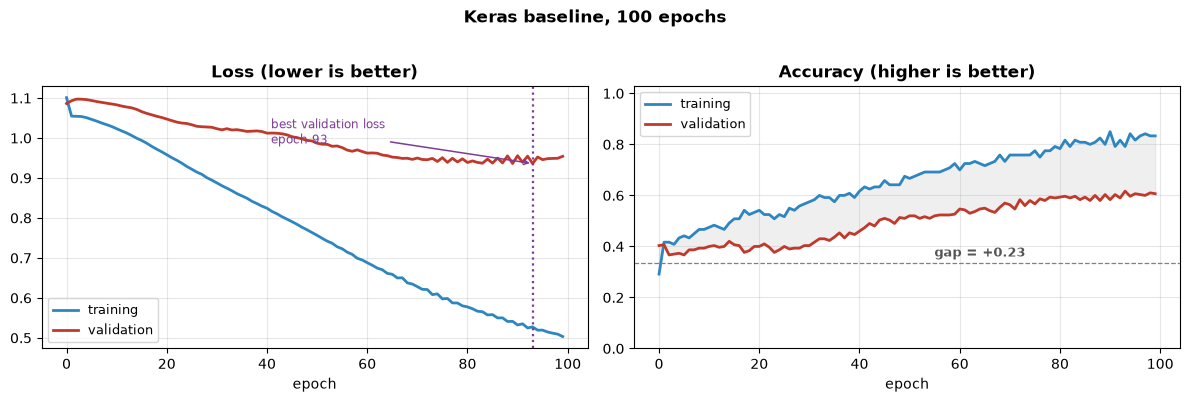

In [11]:
model = build_model()

# TODO: compile with Adam at learning rate 0.02, sparse categorical cross-entropy,
#       and accuracy as a metric
model.compile(optimizer=keras.optimizers.Adam(0.02),
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])

t0 = time.time()
# TODO: fit for 100 epochs, batch_size 32, with X_val/y_val as validation data,
#       and verbose=0.  Keep the returned History.
history = model.fit(X_train, y_train,
                    epochs=100,
                    batch_size=32,
                    validation_data=(X_val, y_val),
                    verbose=0)
print(f"trained in {time.time() - t0:.0f}s")
print(f"trained in {time.time() - t0:.0f}s")

# TODO: evaluate on training and validation data.
#       model.evaluate(..., verbose=0) returns [loss, accuracy]
train_loss, train_acc = model.evaluate(X_train, y_train, verbose=0)
val_loss, val_acc = model.evaluate(X_val, y_val, verbose=0)

print(f"training   : loss {train_loss:.3f}  accuracy {train_acc:.3f}")
print(f"validation : loss {val_loss:.3f}  accuracy {val_acc:.3f}")
print(f"gap        : {train_acc - val_acc:+.3f}")

# --- self-check ---
assert "val_loss" in history.history, "did you pass validation_data?"
assert len(history.history["loss"]) == 100, "100 epochs means 100 recorded losses"
assert train_acc > 0.6, "100 epochs should get well above chance on the training set"
print("\nExercise 2 passed")

fig = draw_overfitting_curves(history_to_rows(history), "Keras baseline, 100 epochs")
plt.show()

The same picture as Lab 6: training loss falling, validation loss levelling off and starting to
rise. Same problem, same diagnosis — reached in four lines instead of three hundred.

> **A detail that catches people out.** The accuracy `fit` prints during training is measured
> *while training*, which with dropout means **with dropout switched on**. Always call `evaluate`
> afterwards for the real number. Keras handles the training/inference distinction for you —
> exactly the `training=True` flag you wired by hand in Lab 6.


# Stage 3 · Regularization, callbacks and data

## Idea 3 — Lab 6, in arguments

Everything you implemented last week is a keyword argument:

| Lab 6 | Keras |
|---|---|
| `weight_regularizer_l2=5e-4` | `layers.Dense(128, kernel_regularizer=regularizers.l2(5e-4))` |
| `weight_regularizer_l1=1e-3` | `regularizers.l1(1e-3)` |
| `Layer_Dropout(0.2)` | `layers.Dropout(0.2)` |
| `batchnorm_forward` | `layers.BatchNormalization()` |

Two of those deserve a comment.

**`kernel_regularizer`** applies to the weights. Keras calls a layer's weight matrix its *kernel*
and its biases its *bias*, so there is a `bias_regularizer` too — and, as in Lab 6, penalising
biases rarely matters much.

**`BatchNormalization`** is the one you could not finish. In Lab 6 you wrote its forward pass and I
told you the backward pass was the hardest derivation in the course. Keras has both. You can now
use it with one line — and, unlike most people who do, you know what it computes.


### Exercise 3 — a regularized model

Your `build_model` already accepts `l2` and `dropout_rate`. Use them, and confirm Keras does what
Lab 6 did.


In [12]:
def compile_and_fit(model, epochs=100, batch_size=32, lr=0.02, callbacks=None, verbose=0):
    """Compile with Adam and fit, returning the History."""
    model.compile(optimizer=keras.optimizers.Adam(lr),
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"])
    return model.fit(X_train, y_train, epochs=epochs, batch_size=batch_size,
                     validation_data=(X_val, y_val), callbacks=callbacks or [],
                     verbose=verbose)


# TODO: build a model with L2 of 5e-4, then fit it with compile_and_fit
model_l2 = build_model(l2=5e-4)
hist_l2 = compile_and_fit(model_l2)

l2_train = model_l2.evaluate(X_train, y_train, verbose=0)
l2_val = model_l2.evaluate(X_val, y_val, verbose=0)
print(f"L2 model   : train acc {l2_train[1]:.3f}   val acc {l2_val[1]:.3f}")

# --- self-check ---
assert model_l2.count_params() == 771, "regularization adds no parameters"
assert model_l2.layers[0].kernel_regularizer is not None, "the first Dense should be regularized"
assert len(model_l2.losses) > 0, \
    "a regularized model carries extra penalty terms in model.losses"
print("\nExercise 3 passed")
penalty = float(sum(model_l2.losses))
print(f"\nthe L2 penalty currently adds {penalty:.4f} to the loss")

L2 model   : train acc 0.825   val acc 0.607

Exercise 3 passed

the L2 penalty currently adds 0.0435 to the loss


---
## Idea 4 — Callbacks: hooks into the training loop

In Lab 6 we noticed validation loss bottoming out around epoch 500 and said *you could just stop
there*. That is **early stopping**, and we did not implement it.

Keras does it with a **callback** — an object `fit` consults at every epoch:

```python
early = keras.callbacks.EarlyStopping(
    monitor="val_loss",            # watch validation loss
    patience=25,                   # tolerate 25 epochs with no improvement
    restore_best_weights=True)     # then rewind to the best epoch
```

`restore_best_weights=True` is the important one. Without it you keep the weights from the
*stopping* epoch, which are worse than the best ones you passed through.

Other callbacks you will meet: `ModelCheckpoint` (save the best model to disk as you go),
`ReduceLROnPlateau` (cut the learning rate when progress stalls — Lab 5's decay, but reactive),
and `TensorBoard` (live training dashboards).


### Exercise 4 — early stopping

In [13]:
# TODO: an EarlyStopping callback watching val_loss, patience 25,
#       restoring the best weights
early = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=25,
    restore_best_weights=True
)

model_es = build_model()
hist_es = compile_and_fit(model_es, epochs=200, callbacks=[early])

epochs_run = len(hist_es.history["loss"])
es_val = model_es.evaluate(X_val, y_val, verbose=0)

print(f"asked for 200 epochs, stopped after {epochs_run}")
print(f"best epoch was {early.best_epoch + 1}, with val loss {early.best:.3f}")
print(f"final validation: loss {es_val[0]:.3f}  accuracy {es_val[1]:.3f}")

# --- self-check ---
assert epochs_run < 200, "early stopping should have stopped before 200 epochs"
assert abs(es_val[0] - early.best) < 0.05, \
    "with restore_best_weights the final loss should match the best one seen"
print("\nExercise 4 passed")

asked for 200 epochs, stopped after 119
best epoch was 94, with val loss 0.936
final validation: loss 0.936  accuracy 0.617

Exercise 4 passed


Early stopping gives you a lower validation loss than the baseline **and** finishes sooner. It
is the cheapest regularizer there is, which is why it is almost always on.

---
## Idea 5 — `tf.data`, and why epochs are not steps

One practical wrinkle. Keras does a chunk of bookkeeping at the end of every **epoch**: evaluating
validation data, updating history, running callbacks. On a real dataset that is nothing. On our 120
samples, where one full-batch epoch is a *single* gradient step, the bookkeeping dominates.

Lab 6 trained for 4,000 steps. Asking Keras for 4,000 epochs would take several minutes for a
second's worth of arithmetic.

The fix is to separate the two ideas. A **`tf.data.Dataset`** is TensorFlow's input pipeline: it
can batch, shuffle, prefetch and repeat forever. Combined with `steps_per_epoch`, you decide how
many updates make up an "epoch":

```python
dataset = tf.data.Dataset.from_tensor_slices((X_train, y_train)).batch(120).repeat()
model.fit(dataset, steps_per_epoch=20, epochs=100, ...)     # 2,000 updates, 100 reports
```

Same 2,000 gradient steps, one twentieth of the overhead. On large datasets `tf.data` matters for a
different reason — it streams data from disk and prepares the next batch while the GPU works on the
current one.


In [14]:
train_ds = (tf.data.Dataset
            .from_tensor_slices((X_train, y_train))
            .batch(len(X_train))        # one batch = the whole training set
            .repeat())                  # loop forever; steps_per_epoch decides when to stop

print("dataset element spec:", train_ds.element_spec)
print("\n2000 updates as 2000 epochs : slow (Keras bookkeeping 2000 times)")
print("2000 updates as 100 epochs   : fast (steps_per_epoch=20)")

dataset element spec: (TensorSpec(shape=(None, 2), dtype=tf.float64, name=None), TensorSpec(shape=(None,), dtype=tf.uint8, name=None))

2000 updates as 2000 epochs : slow (Keras bookkeeping 2000 times)
2000 updates as 100 epochs   : fast (steps_per_epoch=20)


---
## Idea 6 — Saving a model

A trained model is worth keeping. One line each way:

```python
model.save("my_model.keras")                  # architecture + weights + optimizer state
reloaded = keras.models.load_model("my_model.keras")
```

Run the cell: train, save, reload, and confirm the predictions are identical.


In [15]:
model_es.save("spiral_model.keras")
reloaded = keras.models.load_model("spiral_model.keras")

before = model_es.predict(X_val[:5], verbose=0)
after = reloaded.predict(X_val[:5], verbose=0)

print("identical predictions after reload:", np.allclose(before, after))
print("file size:", os.path.getsize("spiral_model.keras"), "bytes")
print("\nreloaded model:")
reloaded.summary()

identical predictions after reload: True
file size: 30336 bytes

reloaded model:


Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_12 (Dense)                │ (None, 128)            │           384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,315 (9.05 KB)

 Trainable params: 771 (3.01 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 1,544 (6.04 KB)

# Stage 4 · Reproduce Lab 6

# Assessment


Last week you spent a lab building regularization in NumPy and ran a four-way showdown. Today you
will run the same experiment in Keras, with the same data and the same 2,000 gradient steps — and
see whether you reach the same conclusions.

Takes about 90 seconds to run.

### Q1 — The showdown, again

In [16]:
def run_config(name, l2=0.0, dropout_rate=0.0, early_stopping=False,
               steps_per_epoch=20, epochs=100, lr=0.02):
    """Build, train for steps_per_epoch * epochs updates, and measure."""
    model = build_model(l2=l2, dropout_rate=dropout_rate)
    model.compile(optimizer=keras.optimizers.Adam(lr),
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"])
    callbacks = []
    if early_stopping:
        callbacks.append(keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=10, restore_best_weights=True))

    hist = model.fit(train_ds, steps_per_epoch=steps_per_epoch, epochs=epochs,
                     validation_data=(X_val, y_val), callbacks=callbacks, verbose=0)

    tr = model.evaluate(X_train, y_train, verbose=0)
    va = model.evaluate(X_val, y_val, verbose=0)
    return model, hist, (tr[1], va[1], va[0])


configs = {
    "baseline":      dict(),
    "L2 (5e-4)":     dict(l2=5e-4),
    "dropout (0.2)": dict(dropout_rate=0.2),
    "early stopping": dict(early_stopping=True),
}

results, models, histories = {}, {}, {}
t0 = time.time()
for name, kwargs in configs.items():
    # TODO: run this configuration and store the model, history and results
    model, hist, scores = run_config(name, **kwargs)
    models[name], histories[name], results[name] = model, hist, scores

print(f"{'model':<16} {'train acc':>10} {'val acc':>9} {'val loss':>10} {'gap':>8}")
print("-" * 58)
for name, (ta, va, vl) in results.items():
    print(f"{name:<16} {ta:>10.3f} {va:>9.3f} {vl:>10.3f} {ta - va:>+8.3f}")
print(f"\n({time.time() - t0:.0f} seconds)")

# --- self-check ---
assert len(results) == 4
base_ta, base_va, base_vl = results["baseline"]
assert base_ta > 0.9, "the baseline should fit the training data very well"
assert base_ta - base_va > 0.15, "and should overfit, as in Lab 6"
for name in ["L2 (5e-4)", "dropout (0.2)", "early stopping"]:
    assert results[name][2] < base_vl, f"{name} should lower validation loss"
print("Q1 passed")

C:\Users\HUAWEI\anaconda3\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


model             train acc   val acc   val loss      gap
----------------------------------------------------------
baseline              0.983     0.720      2.160   +0.263
L2 (5e-4)             0.975     0.730      1.177   +0.245
dropout (0.2)         0.908     0.673      1.899   +0.235
early stopping        0.883     0.623      0.955   +0.260

(58 seconds)
Q1 passed


### Q2 — Look at it

Draw the decision boundaries and the baseline's curves, as in Lab 6.


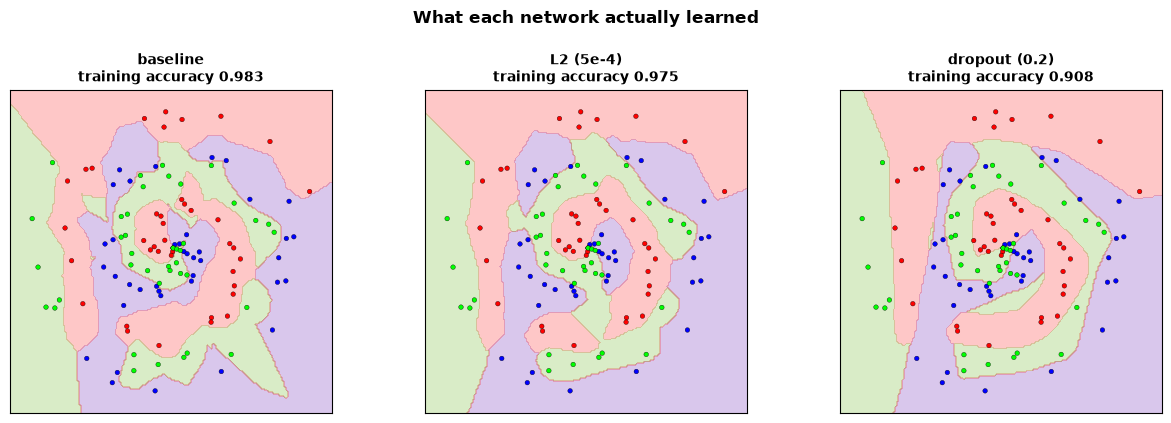

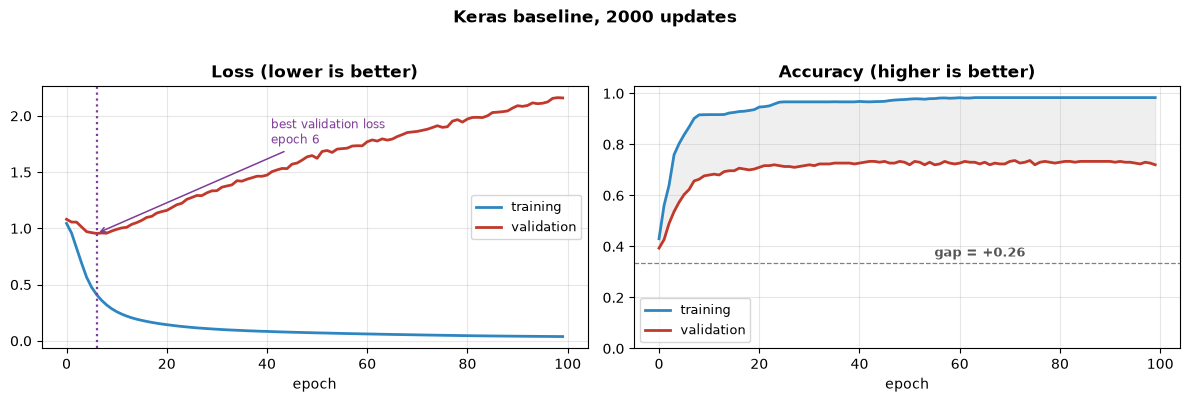

In [17]:
def predictor(model):
    return lambda points: np.argmax(model.predict(points, verbose=0), axis=1)


# TODO: decision boundaries for the baseline, L2 and dropout models
fig = draw_decision_boundaries({"baseline": predictor(models["baseline"]),
                                "L2 (5e-4)": predictor(models["L2 (5e-4)"]),
                                "dropout (0.2)": predictor(models["dropout (0.2)"])},
                               X_train, y_train)
plt.show()

# TODO: the baseline's training curves
fig = draw_overfitting_curves(history_to_rows(histories["baseline"]),
                              "Keras baseline, 2000 updates")
plt.show()

## What you did today

Reproduced six weeks of NumPy in about ten lines — and, more importantly, understood every line.

| You wrote in Labs 1–6 | Today |
|---|---|
| `Layer_Dense`, ReLU, softmax | `layers.Dense(128, activation="relu")` |
| every `backward()` method | automatic differentiation |
| `Optimizer_Adam` | `keras.optimizers.Adam(0.02)` |
| the training loop, `get_batches` | `model.fit(...)`, `tf.data` |
| `regularization_loss`, `Layer_Dropout` | `kernel_regularizer=`, `layers.Dropout(0.2)` |
| `batchnorm_forward` (forward only) | `layers.BatchNormalization()` (both directions) |
| "you could stop at the best epoch" | `EarlyStopping(restore_best_weights=True)` |

### What this does not change

The framework writes the derivatives. It does not understand your problem. Every failure from the
last six weeks is still possible, and now harder to see: a learning rate that explodes, a network
that memorises, dropout left on at the wrong moment, a loss that goes `nan`. You can diagnose
those because you built the pieces.

### Before next week

* Restart the kernel and run everything top to bottom. Every assertion should pass.
* Install PyTorch (`pip install torch`) **before** the lab, or plan to use Colab.
* Skim the Keras layers documentation. You will not remember it; you need to know it is there.

---

### Submission

1. Create a new repository on GitHub for this course and name it `arti402`.
2. Rename this file to `arti402_Lab7_<YourID>.ipynb` and upload the completed notebook, with all
   outputs visible, to your repository.
